# Consolidado: qué aprendimos sobre el suelo de Bogotá

Cinco notebooks, un pipeline de cinco etapas y unas setenta tablas de
resultados. Este documento los reúne y responde dos preguntas: **qué se puede
usar para decidir** y **qué no, aunque lo parezca**.

> **Regla del documento**: aquí no se escribe ninguna cifra a mano. Todas se
> leen de `outputs/tablas/` y de `data/processed/`, igual que hace
> `src/report.py` con el informe del pipeline. Si un notebook se vuelve a
> correr con otros parámetros, este consolidado cambia solo.

## De dónde sale cada cosa

| Fuente | Pregunta que responde | Tablas |
|---|---|---|
| `run_pipeline.py` (etapas 01-05) | ¿cuánto explica la ubicación la intensidad construida? | t01-t16 |
| `comparacion_modelos_pycaret.ipynb` | ¿algún clasificador le gana al Random Forest? | t17-t19 |
| `valor_suelo_pesos_m2.ipynb` | ¿cuánto vale de verdad el m² y sirve el IVS para tasarlo? | t20-t28 |
| `pronostico_valor_suelo.ipynb` | ¿cuánto valdrá y dónde subirá más? | t30-t42 |
| `clusters_comportamiento_mercado.ipynb` | ¿de cuántas maneras se comporta el suelo? | t43-t54 |
| `anomalias_suelo.ipynb` | ¿qué manzanas son raras y en qué año se rompieron? | t55-t62 |

## Cómo está organizado

1. **Lo que sí funciona** — los resultados que soportan una decisión.
2. **Lo que no funciona** — en su propia sección, porque son igual de sólidos y
   evitan errores caros.
3. **Las cinco trampas** — métricas que dan la respuesta equivocada, cada una
   documentada con su número.

**Requisito**: haber ejecutado el pipeline y los cuatro notebooks de
`notebooks/`. Lo que falte se reporta y se omite, sin romper nada.

## 0. Preparación

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config as C

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 96, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
AZUL, VERDE, NARANJA, ROJO, AMARILLO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#e9c46a", "#9aa5ab"
PALETA = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#7b2cbf",
          "#0077b6", "#06d6a0", "#bc6c25", "#8d99ae"]
CMAP_VALOR = "RdYlBu_r"
ASPECTO = 1 / np.cos(np.radians(4.65))

GUARDAR_FIGURAS = False

def guardar_fig(fig, archivo):
    if GUARDAR_FIGURAS:
        fig.savefig(C.FIG_DIR / archivo, facecolor="white")

def pesos(x, pos=None):
    if x >= 1e6:
        return "%.1f M" % (x / 1e6)
    return "%.0f k" % (x / 1e3) if x >= 1e3 else "%.0f" % x

def formato_mapa(ax, titulo=None):
    ax.set_xlim(*C.URB_LON); ax.set_ylim(*C.URB_LAT)
    ax.set_aspect(ASPECTO); ax.set_xlabel("longitud"); ax.grid(alpha=.25)
    if titulo:
        ax.set_title(titulo)
print("raiz:", ROOT)

raiz: C:\Users\Usuario\Proyectos\Catastro_ML


### El cargador

Todo el documento se apoya en `T("t34")`, que busca la tabla por prefijo y
devuelve `None` si no está. Así, si falta un notebook por correr, la celda que
dependa de él lo dice y el resto sigue funcionando.

In [2]:
_TABLAS = {p.name.split("_")[0]: p for p in sorted(C.TAB_DIR.glob("t*.csv"))}

def T(clave, **kw):
    "Lee una tabla de outputs/tablas por su prefijo (t34, t51...). None si no existe."
    p = _TABLAS.get(clave)
    return pd.read_csv(p, **kw) if p else None

def D(nombre, **kw):
    "Lee un csv.gz de data/processed. None si no existe."
    p = C.PROC_DIR / nombre
    return pd.read_csv(p, **kw) if p.exists() else None

def cifra(tabla, fila, columna, filtro=None, pordefecto="n/d"):
    "Extrae un valor concreto de una tabla, tolerando que no exista."
    if tabla is None or columna not in tabla.columns:
        return pordefecto
    d = tabla if filtro is None else tabla[filtro(tabla)]
    if not len(d):
        return pordefecto
    return d.iloc[fila][columna]

presentes = sorted(_TABLAS)
faltan = [c for c in ["t11", "t20", "t25", "t30", "t33", "t34", "t51", "t59"]
          if c not in _TABLAS]
print("tablas encontradas: %d" % len(_TABLAS))
print("rango: %s ... %s" % (presentes[0], presentes[-1]))
if faltan:
    print("\nFALTAN tablas clave (%s): corre los notebooks correspondientes." % ", ".join(faltan))
else:
    print("estan todas las tablas clave")

datos_mz = {n: D(n + ".csv.gz", dtype={"manzana": str, "sector": str})
            for n in ["manzanas_valor_pesos", "pronostico_manzanas",
                      "clusters_manzanas", "anomalias_manzanas"]}
print()
for n, d in datos_mz.items():
    print("  %-26s %s" % (n, "%6d filas x %2d col" % d.shape if d is not None else "AUSENTE"))

tablas encontradas: 68
rango: t01 ... t62
estan todas las tablas clave



  manzanas_valor_pesos        38748 filas x 11 col
  pronostico_manzanas         37442 filas x 12 col
  clusters_manzanas           37442 filas x 22 col
  anomalias_manzanas          37442 filas x 27 col


## 1. El proyecto en una página

In [3]:
stats = json.loads((C.PROC_DIR / "ingest_stats.json").read_text()) if (C.PROC_DIR / "ingest_stats.json").exists() else {}
t20, t30 = T("t20"), T("t30")

filas = []
if stats:
    filas.append(("Construcciones leidas del GeoJSON", "{:,}".format(stats.get("features_leidas", 0))))
    filas.append(("Construcciones validas", "{:,}".format(stats.get("features_validas", 0))))
if datos_mz["pronostico_manzanas"] is not None:
    filas.append(("Manzanas modelables", "{:,}".format(len(datos_mz["pronostico_manzanas"]))))
if t20 is not None:
    filas.append(("Manzanas con precio real de Catastro",
                  "{:,} ({}%)".format(int(t20.iloc[1]["manzanas"]), t20.iloc[1]["porcentaje"])))
if t30 is not None:
    filas.append(("Años de serie de precios", "%d-%d" % (t30["anio"].min(), t30["anio"].max())))
    filas.append(("Precio mediano del m2 de terreno (ultimo año)",
                  pesos(t30["mediana_ciudad"].iloc[-1])))
filas.append(("Tablas de resultados", "{:,}".format(len(_TABLAS))))
filas.append(("Figuras guardadas por el pipeline", "{:,}".format(len(list(C.FIG_DIR.glob("*.png"))))))

panorama = pd.DataFrame(filas, columns=["", "valor"]).set_index("")
panorama

,valor
,
Construcciones leidas del GeoJSON,"2,401,061"
Construcciones validas,"2,388,787"
Manzanas modelables,"37,442"
Manzanas con precio real de Catastro,"38,018 (98.1%)"
Años de serie de precios,2017-2026
Precio mediano del m2 de terreno (ultimo año),2.6 M
Tablas de resultados,68
Figuras guardadas por el pipeline,19


---

# 2. Lo que sí funciona

Cuatro resultados que soportan una decisión, en orden de cuán directamente se
pueden usar.

### 2.1 El precio real del suelo, y quién lo paga

Catastro publica el valor de referencia del **terreno** por manzana. Cubre casi
todo el universo del proyecto, así que no hace falta estimarlo.

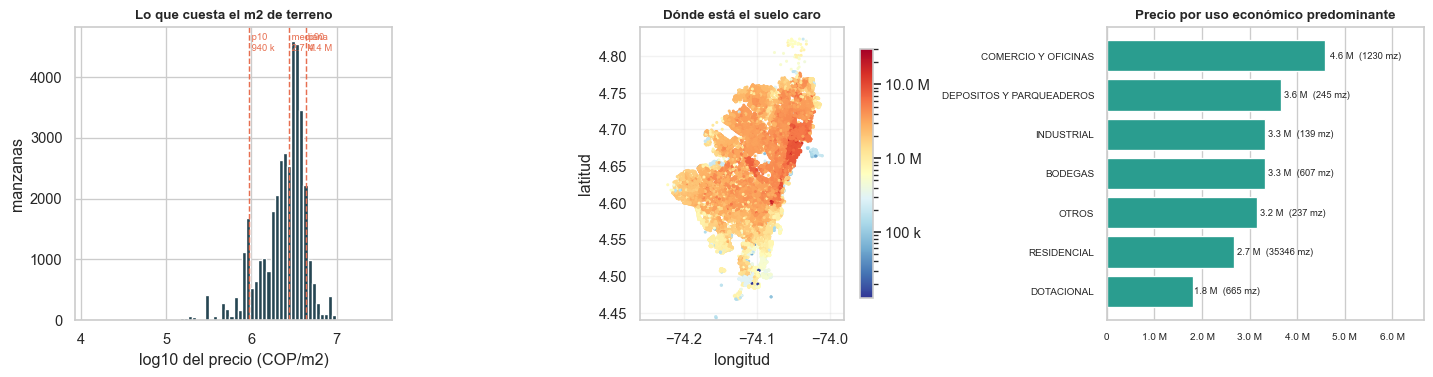

mediana 2.7 M  |  p10 940 k  |  p90 4.4 M  |  razon p90/p10 = 4.6


In [4]:
t27 = T("t27")
mvp = datos_mz["manzanas_valor_pesos"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

if mvp is not None:
    col = "cop_m2_real_2026" if "cop_m2_real_2026" in mvp.columns else "cop_m2"
    v = mvp[col].dropna()
    ax[0].hist(np.log10(v), bins=70, color=AZUL)
    for q, et in [(.1, "p10"), (.5, "mediana"), (.9, "p90")]:
        x = np.log10(v.quantile(q))
        ax[0].axvline(x, color=ROJO, ls="--", lw=1.1)
        ax[0].text(x, ax[0].get_ylim()[1] * .92, " %s\n %s" % (et, pesos(v.quantile(q))),
                   fontsize=7, color=ROJO)
    ax[0].set_xlabel("log10 del precio (COP/m2)"); ax[0].set_ylabel("manzanas")
    ax[0].set_title("Lo que cuesta el m2 de terreno")

    d = mvp[mvp["lon"].between(*C.URB_LON) & mvp["lat"].between(*C.URB_LAT)]
    s = ax[1].scatter(d["lon"], d["lat"], c=d[col], s=1.6, cmap=CMAP_VALOR,
                      norm=plt.matplotlib.colors.LogNorm())
    formato_mapa(ax[1], "Dónde está el suelo caro")
    ax[1].set_ylabel("latitud")
    plt.colorbar(s, ax=ax[1], format=mticker.FuncFormatter(pesos), shrink=.85)

if t27 is not None:
    u = t27.sort_values("precio_mediano")
    b = ax[2].barh(u["uso"], u["precio_mediano"], color=VERDE)
    ax[2].xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
    for r, (p_, n_) in zip(b, zip(u["precio_mediano"], u["manzanas"])):
        ax[2].text(p_ * 1.02, r.get_y() + r.get_height() / 2, "%s  (%d mz)" % (pesos(p_), n_),
                   va="center", fontsize=7)
    ax[2].set_xlim(0, u["precio_mediano"].max() * 1.45)
    ax[2].set_title("Precio por uso económico predominante")
    ax[2].grid(axis="y", alpha=0); ax[2].tick_params(labelsize=7.5)

fig.tight_layout(); guardar_fig(fig, "cons_fig01_precio.png"); plt.show()

if mvp is not None:
    print("mediana %s  |  p10 %s  |  p90 %s  |  razon p90/p10 = %.1f"
          % (pesos(v.median()), pesos(v.quantile(.1)), pesos(v.quantile(.9)),
             v.quantile(.9) / v.quantile(.1)))

### 2.2 Dónde se valoriza Bogotá

El precio de hoy ya está en el mercado; lo que discrimina una decisión es
**dónde crece por encima del promedio**. Al ser una comparación relativa, la
inflación no la afecta.

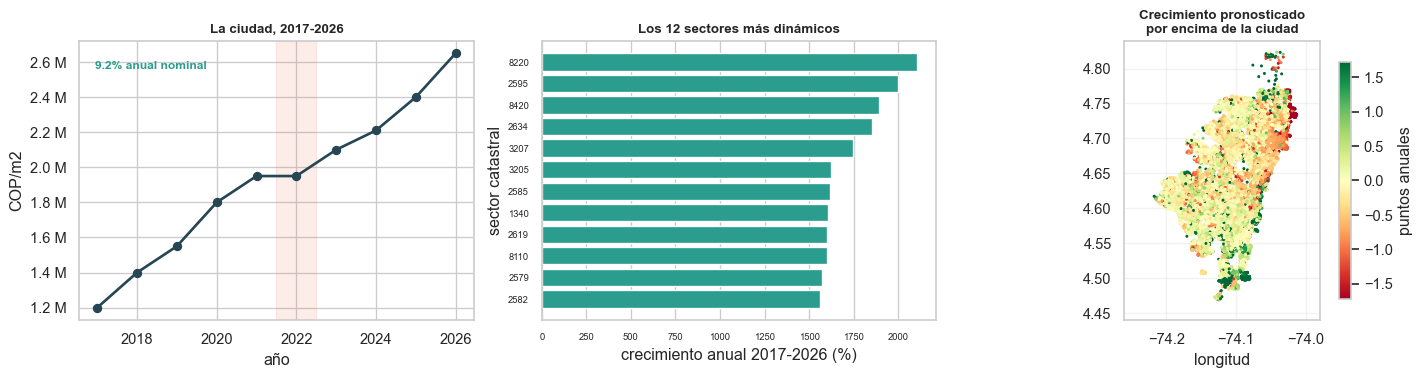

In [5]:
t25, t26 = T("t25"), T("t26")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

if t30 is not None:
    ax[0].plot(t30["anio"], t30["mediana_ciudad"], "o-", color=AZUL, lw=2)
    congelado = t30[t30["pct_sin_cambio"] > 80]
    for a_ in congelado["anio"]:
        ax[0].axvspan(a_ - .5, a_ + .5, color=ROJO, alpha=.12)
    ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
    ax[0].set_xlabel("año"); ax[0].set_ylabel("COP/m2")
    ax[0].set_title("La ciudad, %d-%d" % (t30["anio"].min(), t30["anio"].max()))
    cagr = (t30["mediana_ciudad"].iloc[-1] / t30["mediana_ciudad"].iloc[0]) ** (
        1 / (len(t30) - 1)) - 1
    ax[0].text(.04, .9, "%.1f%% anual nominal" % (100 * cagr), transform=ax[0].transAxes,
               fontsize=9, fontweight="bold", color=VERDE)

if t26 is not None:
    top = t26.nlargest(12, "cagr").iloc[::-1]
    ax[1].barh(top["sector"].astype(str), 100 * top["cagr"], color=VERDE)
    ax[1].set_xlabel("crecimiento anual %d-%d (%%)" % (t30["anio"].min(), t30["anio"].max())
                     if t30 is not None else "crecimiento anual (%)")
    ax[1].set_ylabel("sector catastral")
    ax[1].set_title("Los 12 sectores más dinámicos")
    ax[1].grid(axis="y", alpha=0); ax[1].tick_params(labelsize=7)

pron = datos_mz["pronostico_manzanas"]
if pron is not None:
    d = pron[pron["lon"].between(*C.URB_LON) & pron["lat"].between(*C.URB_LAT)]
    lim = np.nanpercentile(np.abs(d["crec_relativo_pct"]), 96)
    s = ax[2].scatter(d["lon"], d["lat"], c=d["crec_relativo_pct"], s=1.6,
                      cmap="RdYlGn", vmin=-lim, vmax=lim)
    formato_mapa(ax[2], "Crecimiento pronosticado\npor encima de la ciudad")
    plt.colorbar(s, ax=ax[2], label="puntos anuales", shrink=.85)

fig.tight_layout(); guardar_fig(fig, "cons_fig02_valorizacion.png"); plt.show()

### 2.3 Cuánto puede valer en 2030: tres escenarios, no un número

Con diez observaciones anuales, el método que gana el backtest lo hace por poco.
Lo defendible es un rango anclado en lo que la ciudad efectivamente hizo. La
incertidumbre grande no es el modelo: es el escenario macroeconómico.

In [6]:
t32, t33, t42 = T("t32"), T("t33"), T("t42")
if t32 is not None:
    print("Backtest de la deriva de la ciudad (ajuste sin ver los ultimos años):\n")
    print(t32.to_string(index=False))
    print("\nGANA: %s, con %.1f%% de error medio\n"
          % (t32.iloc[0]["modelo"], t32.iloc[0]["error_medio_pct"]))
if t33 is not None:
    print("Escenarios para el pronostico:\n")
    print(t33[["escenario", "crecimiento_anual_pct", "origen"]].to_string(index=False))
t33

Backtest de la deriva de la ciudad (ajuste sin ver los ultimos años):

              modelo  error_medio_pct  error_ultimo_anio_pct  sesgo_pct  crec_anual_implicito_pct
deriva reciente (4a)              1.6                    0.5        1.3                       7.9
    deriva historica              4.9                    4.8        4.9                       9.8
    Holt amortiguado              5.9                   12.0       -5.9                       3.5
 ARIMA(0,1,1)+deriva              6.5                    7.0        6.5                      10.5
    tendencia lineal             10.0                    9.8       10.0                      11.5
  caminata aleatoria             12.7                   20.8      -12.7                       0.0

GANA: deriva reciente (4a), con 1.6% de error medio

Escenarios para el pronostico:

                     escenario  crecimiento_anual_pct                         origen
                          bajo                    4.3  trienio mas flojo

,escenario,deriva_log10_anual,crecimiento_anual_pct,origen
0,bajo,0.0181,4.3,trienio mas flojo (2021-2024)
1,central (deriva reciente (4a)),0.0333,8.0,backtest 2017-2023
2,alto,0.0587,14.5,trienio mas fuerte (2017-2020)


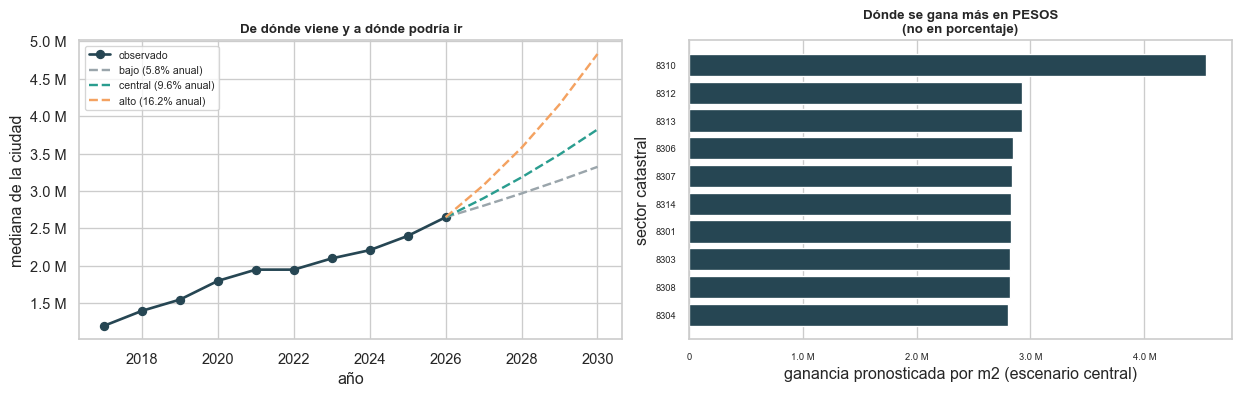

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

if t30 is not None and pron is not None and t33 is not None:
    hist_x = t30["anio"].values
    hist_y = t30["mediana_ciudad"].values
    ax[0].plot(hist_x, hist_y, "o-", color=AZUL, lw=2, label="observado")
    for esc, col in zip(t33["escenario"], [GRIS, VERDE, NARANJA]):
        clave = esc.split(" ")[0]
        c_ = [c for c in pron.columns if c.endswith("_" + clave)]
        if not c_:
            continue
        n_fut = int(c_[0].split("_")[2]) - int(hist_x[-1])   # 'cop_m2_2030_central' -> 4
        fin = pron[c_[0]].median()
        tasa = (fin / hist_y[-1]) ** (1 / n_fut)
        xs = np.arange(hist_x[-1], hist_x[-1] + n_fut + 1)
        ax[0].plot(xs, [hist_y[-1] * tasa ** i for i in range(n_fut + 1)], "--", lw=1.8,
                   color=col, label="%s (%.1f%% anual)" % (clave, 100 * (tasa - 1)))
    ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
    ax[0].set_xlabel("año"); ax[0].set_ylabel("mediana de la ciudad")
    ax[0].set_title("De dónde viene y a dónde podría ir")
    ax[0].legend(fontsize=8)

if t42 is not None:
    top = t42.nlargest(10, "ganancia_cop_m2").iloc[::-1]
    ax[1].barh(top["sector"].astype(str), top["ganancia_cop_m2"], color=AZUL)
    ax[1].xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
    ax[1].set_xlabel("ganancia pronosticada por m2 (escenario central)")
    ax[1].set_ylabel("sector catastral")
    ax[1].set_title("Dónde se gana más en PESOS\n(no en porcentaje)")
    ax[1].grid(axis="y", alpha=0); ax[1].tick_params(labelsize=7)

fig.tight_layout(); guardar_fig(fig, "cons_fig03_escenarios.png"); plt.show()

### 2.4 Seis maneras de comportarse, y dónde está la oportunidad

Los grupos se formaron **sin usar la geografía** —solo precio, valorización,
volatilidad e inercia— y aun así se ordenan sobre el gradiente urbano.

Y una advertencia que vale por sí sola: *"las zonas que más crecen"* es, casi
por definición, *"las zonas más baratas"*. La medida de **oportunidad**
descuenta esa reversión a la media y señala las que crecen más que **sus pares
de precio**.

In [8]:
t51, t53b, t50 = T("t51"), T("t53b"), T("t50")
if t51 is not None:
    v = t51.rename(columns={t51.columns[0]: "grupo"}).set_index("grupo")
    print("Tipologias de comportamiento del suelo:\n")
    print(v[["nombre", "manzanas", "pct", "precio_2026", "cagr_reciente_pct"]].to_string())
if t50 is not None:
    print("\nPureza espacial (fraccion de vecinos que comparten grupo), sin usar coordenadas:")
    print(t50[["version", "silueta", "pureza_espacial"]].to_string(index=False))
t51

Tipologias de comportamiento del suelo:

                                          nombre  manzanas   pct  precio_2026  cagr_reciente_pct
grupo                                                                                           
0                  barato, estancado e inestable       573   1.5     295200.0              -25.0
1                    caro, al ritmo de la ciudad     21985  58.7    3331000.0                7.5
2      barato, al ritmo de la ciudad e inestable       633   1.7    1900000.0                8.6
3                  barato, al ritmo de la ciudad     10799  28.8    1420000.0               10.1
4          medio, al ritmo de la ciudad y quieto      3307   8.8    2670000.0                6.8
5                 barato, acelerando e inestable       145   0.4    1200000.0              102.0

Pureza espacial (fraccion de vecinos que comparten grupo), sin usar coordenadas:
                   version  silueta  pureza_espacial
           libre (K-Means)   0.2796            0

,Unnamed: 0,nombre,manzanas,pct,precio_2026,cagr_total_pct,cagr_reciente_pct,volatilidad,inercia,pron_relativo
0,0,"barato, estancado e inestable",573,1.5,295200.0,1.0,-25.0,0.1834,0.00,4.99
1,1,"caro, al ritmo de la ciudad",21985,58.7,3331000.0,8.2,7.5,0.0266,0.00,-0.07
2,2,"barato, al ritmo de la ciudad e inestable",633,1.7,1900000.0,23.7,8.6,0.2761,0.00,0.11
3,3,"barato, al ritmo de la ciudad",10799,28.8,1420000.0,11.0,10.1,0.0363,0.00,0.17
4,4,"medio, al ritmo de la ciudad y quieto",3307,8.8,2670000.0,6.2,6.8,0.0347,0.25,-0.03
5,5,"barato, acelerando e inestable",145,0.4,1200000.0,9.1,102.0,0.4281,0.00,-8.90


rango de precio de los 12 sectores de mayor oportunidad: 1.2 M a 9.1 M
-> si la medida estuviera mal, todos estarian en el extremo barato


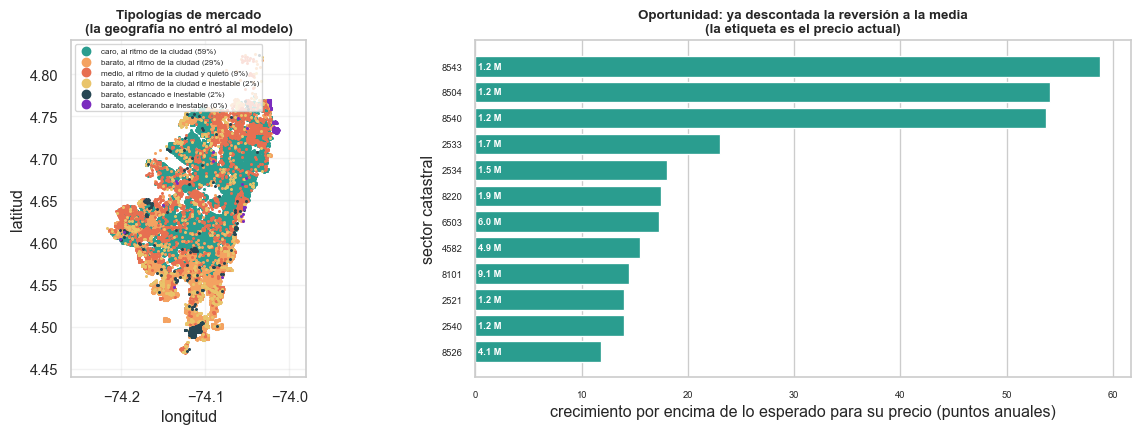

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6))

clu = datos_mz["clusters_manzanas"]
if clu is not None and "cluster" in clu.columns:
    d = clu[clu["lon"].between(*C.URB_LON) & clu["lat"].between(*C.URB_LAT)]
    orden = d["cluster"].value_counts().index            # los chicos, encima
    for c_ in orden:
        m = d["cluster"] == c_
        etq = d.loc[m, "nombre_cluster"].iloc[0] if "nombre_cluster" in d.columns else str(c_)
        ax[0].scatter(d.loc[m, "lon"], d.loc[m, "lat"], s=1.6,
                      color=PALETA[int(c_) % len(PALETA)],
                      label="%s (%.0f%%)" % (etq, 100 * m.mean()))
    formato_mapa(ax[0], "Tipologías de mercado\n(la geografía no entró al modelo)")
    ax[0].set_ylabel("latitud"); ax[0].legend(fontsize=6, markerscale=5, loc="upper left")

if t53b is not None:
    top = t53b.nlargest(12, "oportunidad_pct").iloc[::-1]
    b = ax[1].barh(top["sector"].astype(str), top["oportunidad_pct"], color=VERDE)
    for r, p_ in zip(b, top["precio_2026"]):
        ax[1].text(.3, r.get_y() + r.get_height() / 2, pesos(p_), va="center",
                   fontsize=7, color="white", fontweight="bold")
    ax[1].set_xlabel("crecimiento por encima de lo esperado para su precio (puntos anuales)")
    ax[1].set_ylabel("sector catastral")
    ax[1].set_title("Oportunidad: ya descontada la reversión a la media\n(la etiqueta es el precio actual)")
    ax[1].grid(axis="y", alpha=0); ax[1].tick_params(labelsize=7)
    print("rango de precio de los 12 sectores de mayor oportunidad: %s a %s"
          % (pesos(top["precio_2026"].min()), pesos(top["precio_2026"].max())))
    print("-> si la medida estuviera mal, todos estarian en el extremo barato")

fig.tight_layout(); guardar_fig(fig, "cons_fig04_tipologias.png"); plt.show()

### 2.5 Qué revisar a mano

El detector de anomalías no es un oráculo, es un **filtro**. La tabla dice
exactamente qué se compra con cada nivel de esfuerzo.

In [10]:
t60, t61b, t58 = T("t60"), T("t61b"), T("t58")
if t60 is not None:
    print("Cuantas manzanas revisar y que se encuentra (medido contra anomalias inyectadas):\n")
    print(t60.to_string(index=False))
if t61b is not None:
    print("\nDe las transiciones (manzana, año) mas anomalas:\n")
    print(t61b.to_string())
    print("\nLa mitad son revaluos de zona de Catastro; la otra mitad son manzanas")
    print("que se movieron solas, y esas son las que vale la pena mirar.")
if t58 is not None:
    print("\nTipo de ruptura en la serie de cada manzana:")
    print(t58.to_string(index=False))

Cuantas manzanas revisar y que se encuentra (medido contra anomalias inyectadas):

contaminacion  manzanas_a_revisar  precision_pct  recall_pct
         0.5%                 187           51.9         8.1
         1.0%                 374           37.7        11.8
         2.0%                 748           21.0        13.1
         5.0%                1872            9.8        15.3

De las transiciones (manzana, año) mas anomalas:

                                clasificacion  transiciones   pct
0           aislada: posible señal de mercado          1610  53.7
1  artefacto administrativo (revaluo de zona)          1386  46.3

La mitad son revaluos de zona de Catastro; la otra mitad son manzanas
que se movieron solas, y esas son las que vale la pena mirar.

Tipo de ruptura en la serie de cada manzana:
        tipo_ruptura  manzanas  pct
   sin ruptura clara     16541 44.2
quiebre de tendencia      9638 25.7
               salto      6420 17.1
       congelamiento      2926  7.8
    

---

# 3. Lo que no funciona

Estos resultados son tan sólidos como los anteriores y evitan decisiones caras.
Ninguno es un fracaso del análisis: son propiedades del problema y del dato.

### 3.1 El IVS no sirve para tasar

El índice que construyó el pipeline a partir de la morfología ordena bien la
intensidad edificatoria, para lo que fue diseñado. Como estimador de precio,
**pierde contra asignarle a toda manzana la mediana de la ciudad**.

In [11]:
t22, t28 = T("t22"), T("t28")
if t22 is not None:
    print("Error al convertir el IVS a pesos, medido en sectores que el ajuste no vio:\n")
    print(t22.to_string(index=False))
if t28 is not None:
    rho_ivs = t28.loc[t28["variable"] == "ivs", "spearman_con_precio"]
    rho_ivs = float(rho_ivs.iloc[0]) if len(rho_ivs) else np.nan
    mejores = t28[t28["spearman_con_precio"].abs() > abs(rho_ivs)]
    print("\nCorrelacion con el precio del suelo (Spearman):")
    print("  el IVS                       : %+.3f" % rho_ivs)
    print("  la mejor variable de ubicacion: %+.3f  (%s)"
          % (t28.iloc[0]["spearman_con_precio"], t28.iloc[0]["variable"]))
    print("  variables de ubicacion que le ganan al IVS: %d de %d"
          % (len(mejores), len(t28) - 1))
t28.head(8) if t28 is not None else None

Error al convertir el IVS a pesos, medido en sectores que el ajuste no vio:

              metodo                        conjunto  error_mediano_pct  dentro_de_±30%  r2_log
           Isotonica           ajuste (855 sectores)               34.4            43.2   0.157
           Isotonica prueba (285 sectores no vistos)               33.7            43.6   0.134
          Log-lineal           ajuste (855 sectores)               35.4            42.7   0.129
          Log-lineal prueba (285 sectores no vistos)               34.4            43.8   0.112
Mediana de la ciudad prueba (285 sectores no vistos)               29.4            52.3  -0.082

Correlacion con el precio del suelo (Spearman):
  el IVS                       : +0.327
  la mejor variable de ubicacion: -0.732  (dist_eje_financiero_km)
  variables de ubicacion que le ganan al IVS: 7 de 12


,variable,spearman_con_precio
0,dist_eje_financiero_km,-0.732
1,azimut_cos,0.668
2,lat,0.588
3,dist_aeropuerto_km,-0.567
4,dist_vecino_8_km,0.403
5,vecinos_500m,-0.393
6,vecinos_1km,-0.346
7,ivs,0.327


### 3.2 Ningún modelo transversal le gana a la línea base

Para predecir **cuánto crecerá una manzana por encima de la ciudad** se
compararon once métodos. Varios mejoran el R², pero al calcular el intervalo de
confianza remuestreando **sectores completos** —que es lo correcto, porque dos
manzanas de la misma cuadra no son observaciones independientes— la ventaja se
desvanece.

In [12]:
t34, t38 = T("t34"), T("t38")
if t34 is not None:
    print("Once metodos sobre la misma tarea:\n")
    print(t34.to_string(index=False))
if t38 is not None:
    ganan = t38[t38["supera_a_la_base"] == True]
    print("\nBootstrap por sector: modelos que superan la linea base con 95%% de confianza: %d de %d"
          % (len(ganan), len(t38)))
    print("\nY las metricas tampoco coinciden entre si:")
    for m, c in [("R2", "r2_relativo"), ("error absoluto", "mae_log10"),
                 ("ordenamiento (Spearman)", "spearman")]:
        if c in t34.columns:
            asc = c == "mae_log10"
            print("  mejor por %-24s %s" % (m + ":", t34.sort_values(c, ascending=asc).iloc[0]["modelo"]))

Once metodos sobre la misma tarea:

               modelo  r2_relativo  mae_log10  rmse_log10  error_precio_pct  spearman  acierto_direccion  lift_decil_top
 ensamble (3 mejores)        0.136     0.0185      0.0331               8.0     0.191               57.5            2.97
    arbol de decision        0.110     0.0186      0.0336               7.8     0.174               56.0            4.18
        Random Forest        0.090     0.0192      0.0339               8.7     0.161               55.8            0.88
    Gradient Boosting        0.087     0.0190      0.0340               8.4     0.167               56.5            3.07
          Extra Trees        0.082     0.0192      0.0341               8.5     0.130               55.8            0.56
 reversion a la media        0.060     0.0184      0.0345               7.6     0.318               60.3            6.40
linea base (= ciudad)       -0.003     0.0187      0.0356               7.8       NaN               50.0            0

### 3.3 No hay momentum: lo predecible es la deriva, no la manzana

In [13]:
t31 = T("t31")
if t31 is not None:
    print(t31.to_string(index=False))
    print()
    print("Lectura: el crecimiento es un fenomeno de ZONA (la mayor parte de su varianza")
    print("esta entre sectores), lo que subio no sigue subiendo (momentum ~ 0, y la")
    print("autocorrelacion anual es NEGATIVA), y la unica señal transversal fuerte es que")
    print("lo barato crece mas rapido en porcentaje.")
t31

                                              diagnostico  valor      unidad
           varianza del crecimiento que es entre sectores 93.000           %
        momentum: crecimiento pasado vs futuro (Spearman) -0.085 correlacion
reversion: precio actual vs crecimiento futuro (Spearman) -0.318 correlacion
              autocorrelacion media del crecimiento anual -0.258 correlacion

Lectura: el crecimiento es un fenomeno de ZONA (la mayor parte de su varianza
esta entre sectores), lo que subio no sigue subiendo (momentum ~ 0, y la
autocorrelacion anual es NEGATIVA), y la unica señal transversal fuerte es que
lo barato crece mas rapido en porcentaje.


,diagnostico,valor,unidad
0,varianza del crecimiento que es entre sectores,93.000,%
1,momentum: crecimiento pasado vs futuro (Spearman),-0.085,correlacion
2,reversion: precio actual vs crecimiento futuro...,-0.318,correlacion
3,autocorrelacion media del crecimiento anual,-0.258,correlacion


### 3.4 El insumo es administrativo, no de mercado

`V_REF` lo fija Catastro por zonas y en tandas. Eso deja huellas medibles, y
conviene tenerlas presentes antes de leer cualquier serie como si fuera precio
de transacción.

In [14]:
t55 = T("t55")
if t30 is not None:
    cong = t30[t30["pct_sin_cambio"] > 80]
    print("Años en que Catastro no actualizo practicamente nada:")
    for _, f in cong.iterrows():
        print("  %d: el %.0f%% de las manzanas no se movio" % (f["anio"], f["pct_sin_cambio"]))
if t55 is not None:
    print("\nVecindarios donde todas las manzanas tienen exactamente el mismo valor:")
    print(t55.to_string(index=False))
    print("\nConsecuencia practica: cualquier analisis que compare una manzana con su")
    print("entorno tiene que llevar un piso en el denominador, o divide por cero.")
t55

Años en que Catastro no actualizo practicamente nada:
  2022: el 100% de las manzanas no se movio

Vecindarios donde todas las manzanas tienen exactamente el mismo valor:
        rasgo  pct_vecindarios_identicos  mad_de_la_ciudad
        nivel                       69.8            0.1966
   cagr_total                       55.0            0.0112
cagr_reciente                       63.3            0.0166
  volatilidad                       48.4            0.0147
      inercia                       92.8            0.1043

Consecuencia practica: cualquier analisis que compare una manzana con su
entorno tiene que llevar un piso en el denominador, o divide por cero.


,rasgo,pct_vecindarios_identicos,mad_de_la_ciudad
0,nivel,69.8,0.1966
1,cagr_total,55.0,0.0112
2,cagr_reciente,63.3,0.0166
3,volatilidad,48.4,0.0147
4,inercia,92.8,0.1043


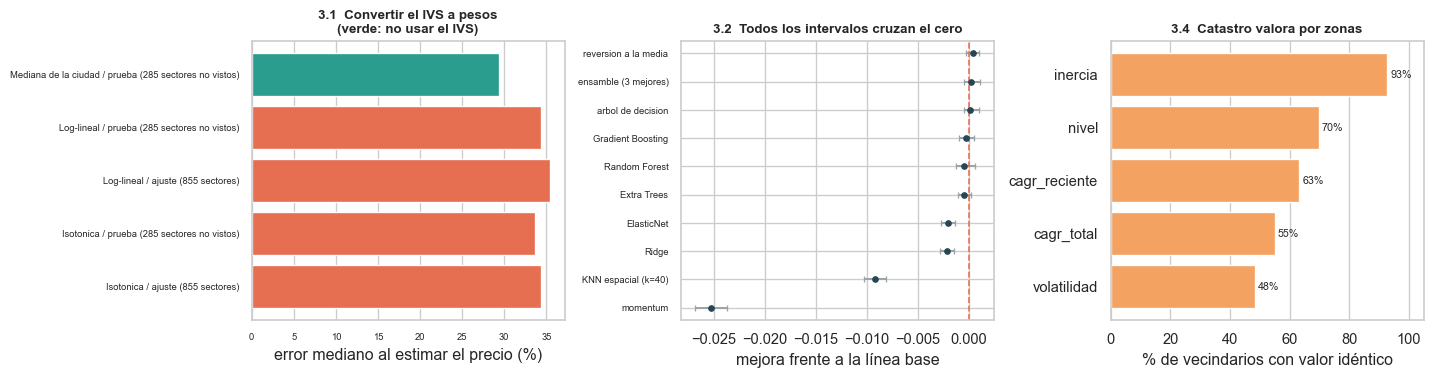

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

if t22 is not None and "error_mediano_pct" in t22.columns:
    d = t22.copy()
    etq = (d["metodo"].astype(str) + " / " + d["conjunto"].astype(str)) if "conjunto" in d else d["metodo"]
    col = [VERDE if "mediana de la ciudad" in str(m).lower() else ROJO for m in d["metodo"]]
    ax[0].barh(etq, d["error_mediano_pct"], color=col)
    ax[0].set_xlabel("error mediano al estimar el precio (%)")
    ax[0].set_title("3.1  Convertir el IVS a pesos\n(verde: no usar el IVS)")
    ax[0].grid(axis="y", alpha=0); ax[0].tick_params(labelsize=7)

if t38 is not None:
    o = t38.iloc[::-1]
    ax[1].errorbar(o["mejora_mae_media"], range(len(o)),
                   xerr=[o["mejora_mae_media"] - o["ic95_bajo"], o["ic95_alto"] - o["mejora_mae_media"]],
                   fmt="o", color=AZUL, ecolor=GRIS, capsize=2.5, ms=4)
    ax[1].axvline(0, color=ROJO, ls="--", lw=1.2)
    ax[1].set_yticks(range(len(o))); ax[1].set_yticklabels(o["modelo"], fontsize=7)
    ax[1].set_xlabel("mejora frente a la línea base")
    ax[1].set_title("3.2  Todos los intervalos cruzan el cero")

if t55 is not None:
    o = t55.sort_values("pct_vecindarios_identicos")
    ax[2].barh(o["rasgo"], o["pct_vecindarios_identicos"], color=NARANJA)
    for i, v_ in enumerate(o["pct_vecindarios_identicos"]):
        ax[2].text(v_ + 1, i, "%.0f%%" % v_, va="center", fontsize=8)
    ax[2].set_xlim(0, 105)
    ax[2].set_xlabel("% de vecindarios con valor idéntico")
    ax[2].set_title("3.4  Catastro valora por zonas")
    ax[2].grid(axis="y", alpha=0)

fig.tight_layout(); guardar_fig(fig, "cons_fig05_lo_que_no.png"); plt.show()

---

# 4. Las cinco trampas

Cada una es una métrica de uso corriente que, en este problema, da la respuesta
equivocada. Las cinco están medidas, no argumentadas.

In [16]:
t35, t37, t39, t47, t59, t10 = T("t35"), T("t37"), T("t39"), T("t47"), T("t59"), T("t10")
trampas = []

if t35 is not None:
    c_niv = [c for c in t35.columns if "precio" in c.lower()]
    c_rel = [c for c in t35.columns if "crecimiento" in c.lower()]
    if c_niv and c_rel:
        quieto = t35[t35["modelo"].str.contains("quieto", case=False, na=False)]
        trampas.append({
            "trampa": "R2 sobre el precio en vez del crecimiento",
            "que parece": "R2 = %.2f para un modelo que dice que nada cambia"
                          % (quieto[c_niv[0]].iloc[0] if len(quieto) else t35[c_niv[0]].max()),
            "que es": "el mejor modelo real solo llega a R2 = %.2f sobre lo que importa"
                      % t35[c_rel[0]].max(),
            "tabla": "t35"})

if t39 is not None and "R2_random_forest" in t39.columns:
    trampas.append({
        "trampa": "Particion aleatoria en vez de temporal",
        "que parece": "R2 = %.2f" % t39["R2_random_forest"].max(),
        "que es": "R2 = %.2f al evaluar en un periodo no visto" % t39["R2_random_forest"].min(),
        "tabla": "t39"})

if t37 is not None:
    peor = t37.loc[t37["diferencia"].idxmin()]
    trampas.append({
        "trampa": "Una variable redundante de mas",
        "que parece": "inofensiva: es la resta de dos columnas ya presentes",
        "que es": "hunde a %s de R2 %.3f a %.3f" % (peor["modelo"],
                                                    peor[t37.columns[1]], peor[t37.columns[2]]),
        "tabla": "t37"})

if t47 is not None:
    mejor_sil = t47.loc[t47["silueta"].idxmax()]
    trampas.append({
        "trampa": "Elegir el clustering por silueta",
        "que parece": "silueta = %.2f con enlace '%s'" % (mejor_sil["silueta"], mejor_sil["enlace"]),
        "que es": "esa particion mete el %.0f%% de las manzanas en un solo grupo"
                  % mejor_sil["grupo_mayor_pct"],
        "tabla": "t47"})

if t59 is not None:
    mejor_roc = t59.loc[t59["roc_auc"].idxmax()]
    mejor_ap = t59.loc[t59["average_precision"].idxmax()]
    trampas.append({
        "trampa": "ROC-AUC con clases desbalanceadas",
        "que parece": "gana %s (ROC %.2f)" % (mejor_roc["detector"], mejor_roc["roc_auc"]),
        "que es": "por precision media gana %s, que tiene ROC %.2f"
                  % (mejor_ap["detector"], mejor_ap["roc_auc"]),
        "tabla": "t59"})

tabla_trampas = pd.DataFrame(trampas)
print("%d trampas documentadas con numeros del propio proyecto:\n" % len(tabla_trampas))
tabla_trampas

5 trampas documentadas con numeros del propio proyecto:



,trampa,que parece,que es,tabla
0,R2 sobre el precio en vez del crecimiento,R2 = 0.68 para un modelo que dice que nada cambia,el mejor modelo real solo llega a R2 = 0.14 so...,t35
1,Particion aleatoria en vez de temporal,R2 = 0.71,R2 = 0.09 al evaluar en un periodo no visto,t39
2,Una variable redundante de mas,inofensiva: es la resta de dos columnas ya pre...,hunde a Random Forest de R2 0.090 a -0.438,t37
3,Elegir el clustering por silueta,silueta = 0.78 con enlace 'average',esa particion mete el 99% de las manzanas en u...,t47
4,ROC-AUC con clases desbalanceadas,gana PCA (reconstruccion) (ROC 0.82),"por precision media gana LOF, que tiene ROC 0.61",t59


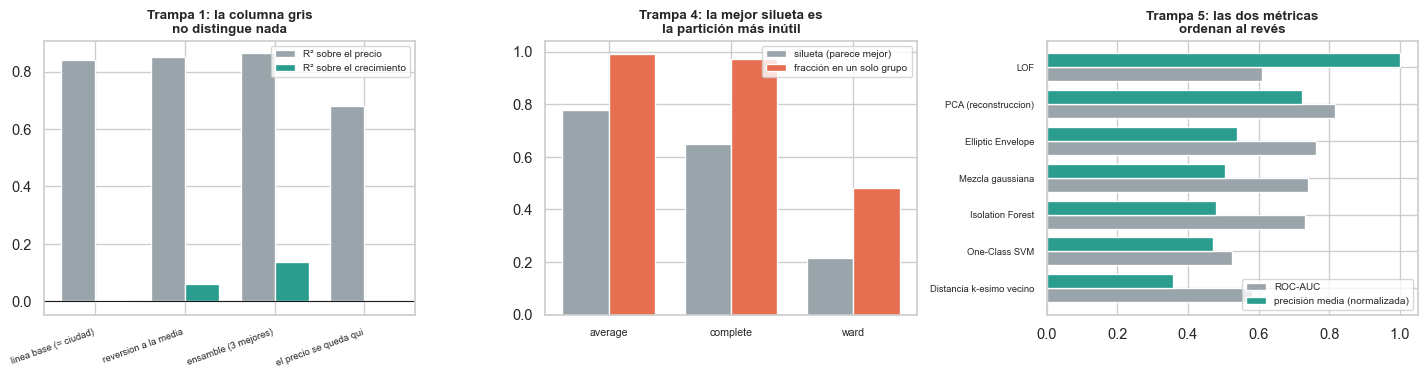

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

if t35 is not None and c_niv and c_rel:
    x = np.arange(len(t35)); w = .38
    ax[0].bar(x - w / 2, t35[c_niv[0]], w, color=GRIS, label="R² sobre el precio")
    ax[0].bar(x + w / 2, t35[c_rel[0]].fillna(0), w, color=VERDE, label="R² sobre el crecimiento")
    ax[0].set_xticks(x); ax[0].set_xticklabels(
        [m[:22] for m in t35["modelo"]], rotation=20, ha="right", fontsize=7)
    ax[0].axhline(0, color="k", lw=.8)
    ax[0].set_title("Trampa 1: la columna gris\nno distingue nada"); ax[0].legend(fontsize=7.5)

if t47 is not None:
    x = np.arange(len(t47)); w = .38
    ax[1].bar(x - w / 2, t47["silueta"], w, color=GRIS, label="silueta (parece mejor)")
    ax[1].bar(x + w / 2, t47["grupo_mayor_pct"] / 100, w, color=ROJO,
              label="fracción en un solo grupo")
    ax[1].set_xticks(x); ax[1].set_xticklabels(t47["enlace"], fontsize=8)
    ax[1].set_title("Trampa 4: la mejor silueta es\nla partición más inútil")
    ax[1].legend(fontsize=7.5)

if t59 is not None:
    o = t59.sort_values("average_precision")
    y = np.arange(len(o)); w = .38
    ax[2].barh(y - w / 2, o["roc_auc"], w, color=GRIS, label="ROC-AUC")
    ax[2].barh(y + w / 2, o["average_precision"] / o["average_precision"].max(), w,
               color=VERDE, label="precisión media (normalizada)")
    ax[2].set_yticks(y); ax[2].set_yticklabels(o["detector"], fontsize=7)
    ax[2].set_title("Trampa 5: las dos métricas\nordenan al revés"); ax[2].legend(fontsize=7.5)

fig.tight_layout(); guardar_fig(fig, "cons_fig06_trampas.png"); plt.show()

---

# 5. El tablero final

In [18]:
def _f(v, fmt="%s"):
    return fmt % v if v not in (None, "n/d") and v == v else "n/d"

tablero = []
if t30 is not None:
    cagr = (t30["mediana_ciudad"].iloc[-1] / t30["mediana_ciudad"].iloc[0]) ** (1 / (len(t30) - 1)) - 1
    tablero.append(("Precio mediano del m2 hoy", pesos(t30["mediana_ciudad"].iloc[-1]), "si"))
    tablero.append(("Crecimiento historico de la ciudad", "%.1f%% anual nominal" % (100 * cagr), "si"))
if t33 is not None:
    tablero.append(("Rango defendible a 4 años",
                    "%.1f%% a %.1f%% anual" % (t33["crecimiento_anual_pct"].min(),
                                               t33["crecimiento_anual_pct"].max()), "si"))
if t32 is not None:
    tablero.append(("Mejor metodo para la deriva",
                    "%s (%.1f%% de error)" % (t32.iloc[0]["modelo"], t32.iloc[0]["error_medio_pct"]), "si"))
if t51 is not None:
    tablero.append(("Tipologias de comportamiento", "%d grupos" % len(t51), "si"))
if t60 is not None:
    f = t60.iloc[0]
    tablero.append(("Filtro de anomalias",
                    "revisar %d manzanas -> %.0f%% son reales" % (f["manzanas_a_revisar"],
                                                                  f["precision_pct"]), "si"))
if t22 is not None:
    peor_ = t22["error_mediano_pct"].max(); mejor_ = t22["error_mediano_pct"].min()
    tablero.append(("Convertir el IVS a pesos",
                    "%.0f%% de error, peor que no usarlo (%.0f%%)" % (peor_, mejor_), "no"))
if t38 is not None:
    tablero.append(("Modelos que baten la linea base",
                    "%d de %d" % (int((t38["supera_a_la_base"] == True).sum()), len(t38)), "no"))
if t31 is not None:
    mom = t31[t31["diagnostico"].str.contains("momentum", case=False, na=False)]
    if len(mom):
        tablero.append(("Momentum del crecimiento", "%.3f (no existe)" % mom.iloc[0]["valor"], "no"))
if t39 is not None:
    tablero.append(("Optimismo de una particion aleatoria",
                    "+%.2f de R2" % (t39["R2_random_forest"].max() - t39["R2_random_forest"].min()), "no"))

tab = pd.DataFrame(tablero, columns=["hallazgo", "cifra", "accionable"])
tab["accionable"] = tab["accionable"].map({"si": "usable", "no": "advertencia"})
print("Todo lo anterior, en una tabla:\n")
tab

Todo lo anterior, en una tabla:



,hallazgo,cifra,accionable
0,Precio mediano del m2 hoy,2.6 M,usable
1,Crecimiento historico de la ciudad,9.2% anual nominal,usable
2,Rango defendible a 4 años,4.3% a 14.5% anual,usable
3,Mejor metodo para la deriva,deriva reciente (4a) (1.6% de error),usable
4,Tipologias de comportamiento,6 grupos,usable
5,Filtro de anomalias,revisar 187 manzanas -> 52% son reales,usable
6,Convertir el IVS a pesos,"35% de error, peor que no usarlo (29%)",advertencia
7,Modelos que baten la linea base,0 de 10,advertencia
8,Momentum del crecimiento,-0.085 (no existe),advertencia
9,Optimismo de una particion aleatoria,+0.62 de R2,advertencia


## 6. Síntesis

**Lo que el proyecto permite decidir hoy**

1. **Dónde está caro y dónde se valoriza.** El precio real del terreno está
   disponible para casi todas las manzanas, la serie cubre una década y el mapa
   de crecimiento relativo señala los corredores que se despegan. Esto no
   necesita ningún modelo: es dato.
2. **Con qué rango trabajar a cuatro años.** El pronóstico aporta escenarios,
   no un número, y el método que gana el backtest es de los simples.
3. **Qué tipo de zona es cada zona.** Las seis tipologías describen el
   comportamiento y se validan contra variables que no entraron al modelo.
4. **Qué mirar a mano.** El filtro de anomalías prioriza y, sobre todo, separa
   los revalúos administrativos de las manzanas que se movieron solas.

**Lo que el proyecto permite evitar**

5. **No tasar con el IVS.** Es un índice de intensidad constructiva, no un
   avalúo, y convertirlo a pesos es peor que usar la mediana de la ciudad.
6. **No creerle a un modelo transversal sin intervalo de confianza.** Con
   bootstrap por sector, ninguno de los once gana.
7. **No extrapolar la tendencia de una manzana.** El momentum no existe en esta
   serie; la autocorrelación anual es negativa.
8. **No leer `V_REF` como precio de transacción.** Hay años congelados y zonas
   enteras con el mismo valor.

**El límite real**

No está en los algoritmos —se probaron más de treinta— sino en el insumo.
Licencias de construcción, planes parciales, obra nueva y transacciones
notariales son las variables que explicarían *por qué* se mueve el precio del
suelo, y ninguna está en los servicios públicos que alimentan este proyecto. Ese
es el siguiente paso, y es un problema de datos, no de modelado.